# Phân tích AI Exposure theo cụm

In [1]:
from pathlib import Path
import sqlite3
import pandas as pd

DB_PATH = Path("../data/database/career.db")
ASSIGNMENT_PATH = Path(
    "../outputs/kmeans_experiments/work_activities_41_lv_k4.csv"
)
OUTPUT_DIR = Path("../outputs/cluster_analysis")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
# 1. Đọc nhãn cụm
assignments = pd.read_csv(ASSIGNMENT_PATH)

cluster_col = 'cluster_id'

if cluster_col is None:
    raise ValueError(
        f"Không tìm thấy cột cluster. Các cột hiện có: "
        f"{assignments.columns.tolist()}"
    )

assignments = assignments[
    ["occupation_code", cluster_col]
].rename(columns={cluster_col: "cluster"})

assignments = assignments.drop_duplicates("occupation_code")


In [3]:
# 2. Đọc điểm AI Exposure
with sqlite3.connect(DB_PATH) as conn:
    occupations = pd.read_sql_query(
        """
        SELECT occupation_code, occupation_title, ai_exposure_score
        FROM occupations
        """,
        conn
    )

In [4]:
# 3. Ghép dữ liệu bằng occupation_code
df = assignments.merge(occupations,
                       how='left',
                       on='occupation_code',
                       validate='one_to_one')


In [5]:
df.head()

,occupation_code,cluster,occupation_title,ai_exposure_score
0,11-1011.00,2,Chief Executives,0.491063
1,11-1011.03,2,Chief Sustainability Officers,0.696279
2,11-1021.00,2,General and Operations Managers,0.739312
3,11-2011.00,1,Advertising and Promotions Managers,0.738163
4,11-2021.00,2,Marketing Managers,0.742922


In [6]:
# 4. Thống kê coverage và phân phối điểm
rows = []

for cluster_id, group in df.groupby("cluster", sort=True):
    scores = group["ai_exposure_score"].dropna()

    rows.append({
        "cluster": cluster_id,
        "n_occupations": len(group),
        "n_with_exposure": len(scores),
        "n_missing_exposure": group["ai_exposure_score"].isna().sum(),
        "coverage_pct": (
            len(scores) / len(group) * 100 if len(group) else 0
        ),
        "mean": scores.mean(),
        "median": scores.median(),
        "std": scores.std(),
        "min": scores.min(),
        "q1": scores.quantile(0.25),
        "q3": scores.quantile(0.75),
        "max": scores.max(),
        "iqr": scores.quantile(0.75) - scores.quantile(0.25)
    })

summary = pd.DataFrame(rows)

In [9]:
summary.head()

,cluster,n_occupations,n_with_exposure,n_missing_exposure,coverage_pct,mean,median,std,min,q1,q3,max,iqr
0,0,204,198,6,97.058824,0.922075,0.931058,0.051550,0.725509,0.894432,0.960112,1.000000,0.065681
1,1,221,210,11,95.022624,0.822129,0.821893,0.097539,0.586849,0.747773,0.907741,1.000000,0.159968
2,2,258,247,11,95.736434,0.767957,0.763492,0.082506,0.491063,0.710702,0.820870,0.974093,0.110168
3,3,228,224,4,98.245614,0.869785,0.874210,0.063322,0.564766,0.836418,0.913564,1.000000,0.077147


In [10]:
summary.to_csv(
    OUTPUT_DIR / "ai_exposure_by_cluster.csv",
    index=False,
    encoding="utf-8-sig"
)

# 5. Lưu dữ liệu đã ghép để kiểm tra và vẽ biểu đồ
df.to_csv(
    OUTPUT_DIR / "occupation_cluster_ai_exposure.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n===== AI EXPOSURE BY CLUSTER =====")
print(summary.round(3).to_string(index=False))

print("\nSố dòng assignment:", len(assignments))
print("Số dòng sau khi ghép:", len(df))
print("Số nghề thiếu thông tin AI Exposure:",
      df["ai_exposure_score"].isna().sum())

print("\nĐã lưu:")
print(OUTPUT_DIR / "ai_exposure_by_cluster.csv")
print(OUTPUT_DIR / "occupation_cluster_ai_exposure.csv")


===== AI EXPOSURE BY CLUSTER =====
 cluster  n_occupations  n_with_exposure  n_missing_exposure  coverage_pct  mean  median   std   min    q1    q3   max   iqr
       0            204              198                   6        97.059 0.922   0.931 0.052 0.726 0.894 0.960 1.000 0.066
       1            221              210                  11        95.023 0.822   0.822 0.098 0.587 0.748 0.908 1.000 0.160
       2            258              247                  11        95.736 0.768   0.763 0.083 0.491 0.711 0.821 0.974 0.110
       3            228              224                   4        98.246 0.870   0.874 0.063 0.565 0.836 0.914 1.000 0.077

Số dòng assignment: 911
Số dòng sau khi ghép: 911
Số nghề thiếu thông tin AI Exposure: 32

Đã lưu:
..\outputs\cluster_analysis\ai_exposure_by_cluster.csv
..\outputs\cluster_analysis\occupation_cluster_ai_exposure.csv


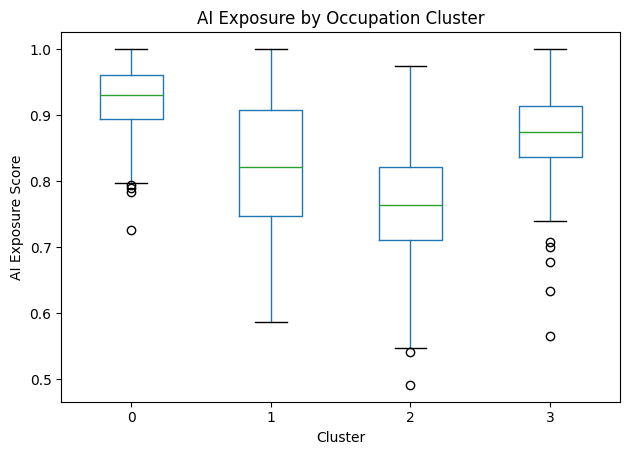


===== KRUSKAL-WALLIS TEST =====
H statistic: 329.5844
p-value: 3.9255166e-71
Có bằng chứng thống kê rằng ít nhất một cụm có phân phối AI Exposure khác biệt.


In [11]:

import matplotlib.pyplot as plt
from scipy.stats import kruskal

# Chỉ sử dụng nghề có AI Exposure
plot_df = df.dropna(subset=["ai_exposure_score"]).copy()

# 1. Boxplot
plot_df.boxplot(
    column="ai_exposure_score",
    by="cluster",
    grid=False
)

plt.title("AI Exposure by Occupation Cluster")
plt.suptitle("")
plt.xlabel("Cluster")
plt.ylabel("AI Exposure Score")
plt.tight_layout()

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
plt.savefig(
    OUTPUT_DIR / "ai_exposure_boxplot.png",
    dpi=150
)
plt.show()

# 2. Kiểm định Kruskal-Wallis
groups = [
    group["ai_exposure_score"].to_numpy()
    for _, group in plot_df.groupby("cluster", sort=True)
]

statistic, p_value = kruskal(*groups)

print("\n===== KRUSKAL-WALLIS TEST =====")
print(f"H statistic: {statistic:.4f}")
print(f"p-value: {p_value:.8g}")

if p_value < 0.05:
    print(
        "Có bằng chứng thống kê rằng ít nhất một cụm "
        "có phân phối AI Exposure khác biệt."
    )
else:
    print(
        "Chưa đủ bằng chứng thống kê để kết luận "
        "phân phối AI Exposure khác nhau giữa các cụm."
    )


In [12]:
# Kiểm tra hậu nghiệm


from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

# Chuẩn bị điểm AI Exposure theo cụm
cluster_scores = {
    cluster_id: group["ai_exposure_score"].to_numpy()
    for cluster_id, group in plot_df.groupby("cluster", sort=True)
}

results = []

# So sánh từng cặp cụm
for cluster_a, cluster_b in combinations(cluster_scores.keys(), 2):
    a = cluster_scores[cluster_a]
    b = cluster_scores[cluster_b]

    test = mannwhitneyu(
        a, b,
        alternative="two-sided"
    )

    # Rank-biserial correlation:
    # Giá trị tuyệt đối càng gần 1, khác biệt theo thứ hạng càng lớn.
    # Dấu cho biết hướng khác biệt theo thứ tự a so với b.
    effect_size = 2 * test.statistic / (len(a) * len(b)) - 1

    results.append({
        "cluster_a": cluster_a,
        "cluster_b": cluster_b,
        "n_a": len(a),
        "n_b": len(b),
        "median_a": float(pd.Series(a).median()),
        "median_b": float(pd.Series(b).median()),
        "median_difference_a_minus_b": (
            float(pd.Series(a).median())
            - float(pd.Series(b).median())
        ),
        "U_statistic": test.statistic,
        "p_raw": test.pvalue,
        "rank_biserial": effect_size
    })

pairwise = pd.DataFrame(results)

# Hiệu chỉnh Holm cho 6 phép kiểm định
pairwise["p_holm"] = multipletests(
    pairwise["p_raw"],
    method="holm"
)[1]

pairwise["significant_0.05"] = pairwise["p_holm"] < 0.05

pairwise.to_csv(
    OUTPUT_DIR / "ai_exposure_pairwise_tests.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n===== PAIRWISE MANN-WHITNEY TESTS =====")
print(
    pairwise[
        [
            "cluster_a", "cluster_b",
            "median_a", "median_b",
            "median_difference_a_minus_b",
            "p_raw", "p_holm",
            "rank_biserial", "significant_0.05"
        ]
    ].round(5).to_string(index=False)
)



===== PAIRWISE MANN-WHITNEY TESTS =====
 cluster_a  cluster_b  median_a  median_b  median_difference_a_minus_b  p_raw  p_holm  rank_biserial  significant_0.05
         0          1   0.93106   0.82189                      0.10917    0.0     0.0        0.59687              True
         0          2   0.93106   0.76349                      0.16757    0.0     0.0        0.87417              True
         0          3   0.93106   0.87421                      0.05685    0.0     0.0        0.50072              True
         1          2   0.82189   0.76349                      0.05840    0.0     0.0        0.31710              True
         1          3   0.82189   0.87421                     -0.05232    0.0     0.0       -0.30006              True
         2          3   0.76349   0.87421                     -0.11072    0.0     0.0       -0.68031              True


In [7]:

# Chỉ giữ các occupation có AI Exposure
valid_df = df.dropna(subset=["ai_exposure_score"]).copy()

overall_mean = valid_df["ai_exposure_score"].mean()
overall_median = valid_df["ai_exposure_score"].median()

print("===== OVERALL AI EXPOSURE =====")
print(f"Number of occupations: {len(valid_df)}")
print(f"Overall mean: {overall_mean:.4f}")
print(f"Overall median: {overall_median:.4f}")

cluster_summary = (
    valid_df.groupby("cluster")["ai_exposure_score"]
    .agg(["count", "mean", "median", "std"])
)

cluster_summary["mean_vs_overall"] = (
    cluster_summary["mean"] - overall_mean
)

cluster_summary["median_vs_overall"] = (
    cluster_summary["median"] - overall_median
)

print("\n===== CLUSTER VS OVERALL =====")
print(cluster_summary.round(4))


===== OVERALL AI EXPOSURE =====
Number of occupations: 879
Overall mean: 0.8416
Overall median: 0.8557

===== CLUSTER VS OVERALL =====
         count    mean  median     std  mean_vs_overall  median_vs_overall
cluster                                                                   
0          198  0.9221  0.9311  0.0515           0.0805             0.0753
1          210  0.8221  0.8219  0.0975          -0.0194            -0.0338
2          247  0.7680  0.7635  0.0825          -0.0736            -0.0922
3          224  0.8698  0.8742  0.0633           0.0282             0.0185
